# Docling - DocLayNet layout pipeline

In [7]:
from pathlib import Path
import os
import subprocess
import sys

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "methods").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "methods").is_dir():
    raise FileNotFoundError("Không tìm thấy thư mục gốc repository; hãy mở notebook từ project DO-AN-261.")

METHOD = "docling"
DATASET = "doclaynet"
SPLIT = "train"
IOU_THRESHOLD = 0.5
LIMIT = 0  # 0: toàn bộ ảnh trong tập dữ liệu; hoặc giới hạn số ảnh (vd: 20)
FORCE_INFERENCE = False  # True: chạy lại inference và ghi đè; False: chỉ chạy ảnh chưa có prediction định dạng mới
FIGURE_LIMIT = 20

PREDICTIONS_DIR = ROOT / "outputs" / "predictions" / METHOD / DATASET
FIGURES_DIR = ROOT / "outputs" / "reports" / f"{METHOD}_{DATASET}"
print(f"Project: {ROOT}")
print(f"Pipeline: {METHOD} | {DATASET}/{SPLIT} | IoU >= {IOU_THRESHOLD}")
print(f"Inference: {'force rerun' if FORCE_INFERENCE else 'skip existing predictions'}")
print(f"Predictions: {PREDICTIONS_DIR}")
print(f"Figures: {FIGURES_DIR}")

def run_script(command):
    """Chạy script con, in log trực tiếp ra notebook; nếu script lỗi thì log lỗi gốc nằm ngay phía trên."""
    command = [str(part) for part in command]
    print("Running:", " ".join(command), flush=True)
    env = {**os.environ, "PYTHONUNBUFFERED": "1", "PYTHONIOENCODING": "utf-8"}
    process = subprocess.Popen(
        command, cwd=ROOT, env=env, text=True, encoding="utf-8", errors="replace",
        stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
    )
    for line in process.stdout:
        if "Loading weights" not in line:
            print(line, end="", flush=True)
    if process.wait() != 0:
        raise RuntimeError(f"{Path(command[1]).name} thất bại (exit code {process.returncode}), xem log phía trên.")

Project: D:\DLA\DO-AN-261
Pipeline: docling | doclaynet/train | IoU >= 0.5
Inference: skip existing predictions
Predictions: D:\DLA\DO-AN-261\outputs\predictions\docling\doclaynet
Figures: D:\DLA\DO-AN-261\outputs\reports\docling_doclaynet


## 1. Prediction

Inference processes local dataset images. Existing predictions are skipped by default; set `FORCE_INFERENCE = True` to overwrite them.

In [8]:
inference_script = ROOT / "methods" / METHOD / "src" / "run_inference.py"
command = [
    sys.executable,
    str(inference_script),
    "--dataset", DATASET,
    "--limit", str(LIMIT),
    "--force" if FORCE_INFERENCE else "--skip-existing",
]
# Docling/torch đôi khi crash ở tầng native (segfault) sau ~1000 ảnh liên tục.
# --skip-existing giúp lần chạy sau tiếp tục từ ảnh còn thiếu, nên tự chạy lại vài lần.
# Sau lần đầu luôn dùng --skip-existing để không chạy lại các ảnh vừa xong.
MAX_ATTEMPTS = 5
for attempt in range(1, MAX_ATTEMPTS + 1):
    try:
        run_script(command)
        break
    except RuntimeError as exc:
        if attempt == MAX_ATTEMPTS:
            raise
        print(f"\n[notebook] Lần {attempt} thất bại ({exc}). Chạy tiếp các ảnh còn thiếu...\n")
        command[-1] = "--skip-existing"
print(f"Predictions: {PREDICTIONS_DIR}")

Running: c:\Users\Admin\AppData\Local\Programs\Python\Python312\python.exe D:\DLA\DO-AN-261\methods\docling\src\run_inference.py --dataset doclaynet --limit 0 --skip-existing
[docling] 0 image(s) to predict from D:\DLA\DO-AN-261\datasets\doclaynet\processed\images (existing predictions skipped)
[docling] No work to do. Predictions are in D:\DLA\DO-AN-261\outputs\predictions\docling\doclaynet
Predictions: D:\DLA\DO-AN-261\outputs\predictions\docling\doclaynet


## 2. Metrics and Evaluation Chart

Đánh giá kết quả trên tập ảnh vừa thực thi inference (`outputs/predictions/docling/doclaynet/`).
- **Strict**: Yêu cầu khớp cả tọa độ (IoU >= threshold) và đúng nhãn.
- **Loose**: Chỉ đánh giá khả năng định vị (localization), bỏ qua nhãn.
- **COCO mAP / AR**: mAP@[.5:.95], AP50, AP75, AR (cả theo kích thước) và AP theo từng class.
- **Runtime**: thời gian xử lý mỗi trang (mean/median/p95, không tính load model), peak RAM/VRAM.
- **Biểu đồ**: Trực quan hóa Precision, Recall, F1 theo từng class và so sánh Strict vs Loose.

Running: c:\Users\Admin\AppData\Local\Programs\Python\Python312\python.exe D:\DLA\DO-AN-261\scripts\evaluate_predictions.py --method docling --dataset doclaynet --split train --iou-threshold 0.5 --loose --plot D:\DLA\DO-AN-261\outputs\reports\docling_doclaynet\metrics_chart.png
Evaluation: docling on doclaynet/train | 1928 images | GT=24,229 boxes | Predictions=24,107 boxes | IoU >= 0.5

=== Strict (location and class) ===
Micro: Precision=0.875  Recall=0.870  F1=0.872  TP=21084 FP=3023 FN=3145  mean IoU=0.929
Macro (mean across 10 ground-truth classes): Precision=0.741  Recall=0.719  F1=0.729
Class                   GT    Pred     TP     FP     FN     Prec   Recall       F1
Text                 12606   12464  11275   1189   1331    0.905    0.894    0.899
Section-header        4451    4598   3823    775    628    0.831    0.859    0.845
Page-footer           1552    1542   1408    134    144    0.913    0.907    0.910
Table                 1456    1422   1347     75    109    0.947   

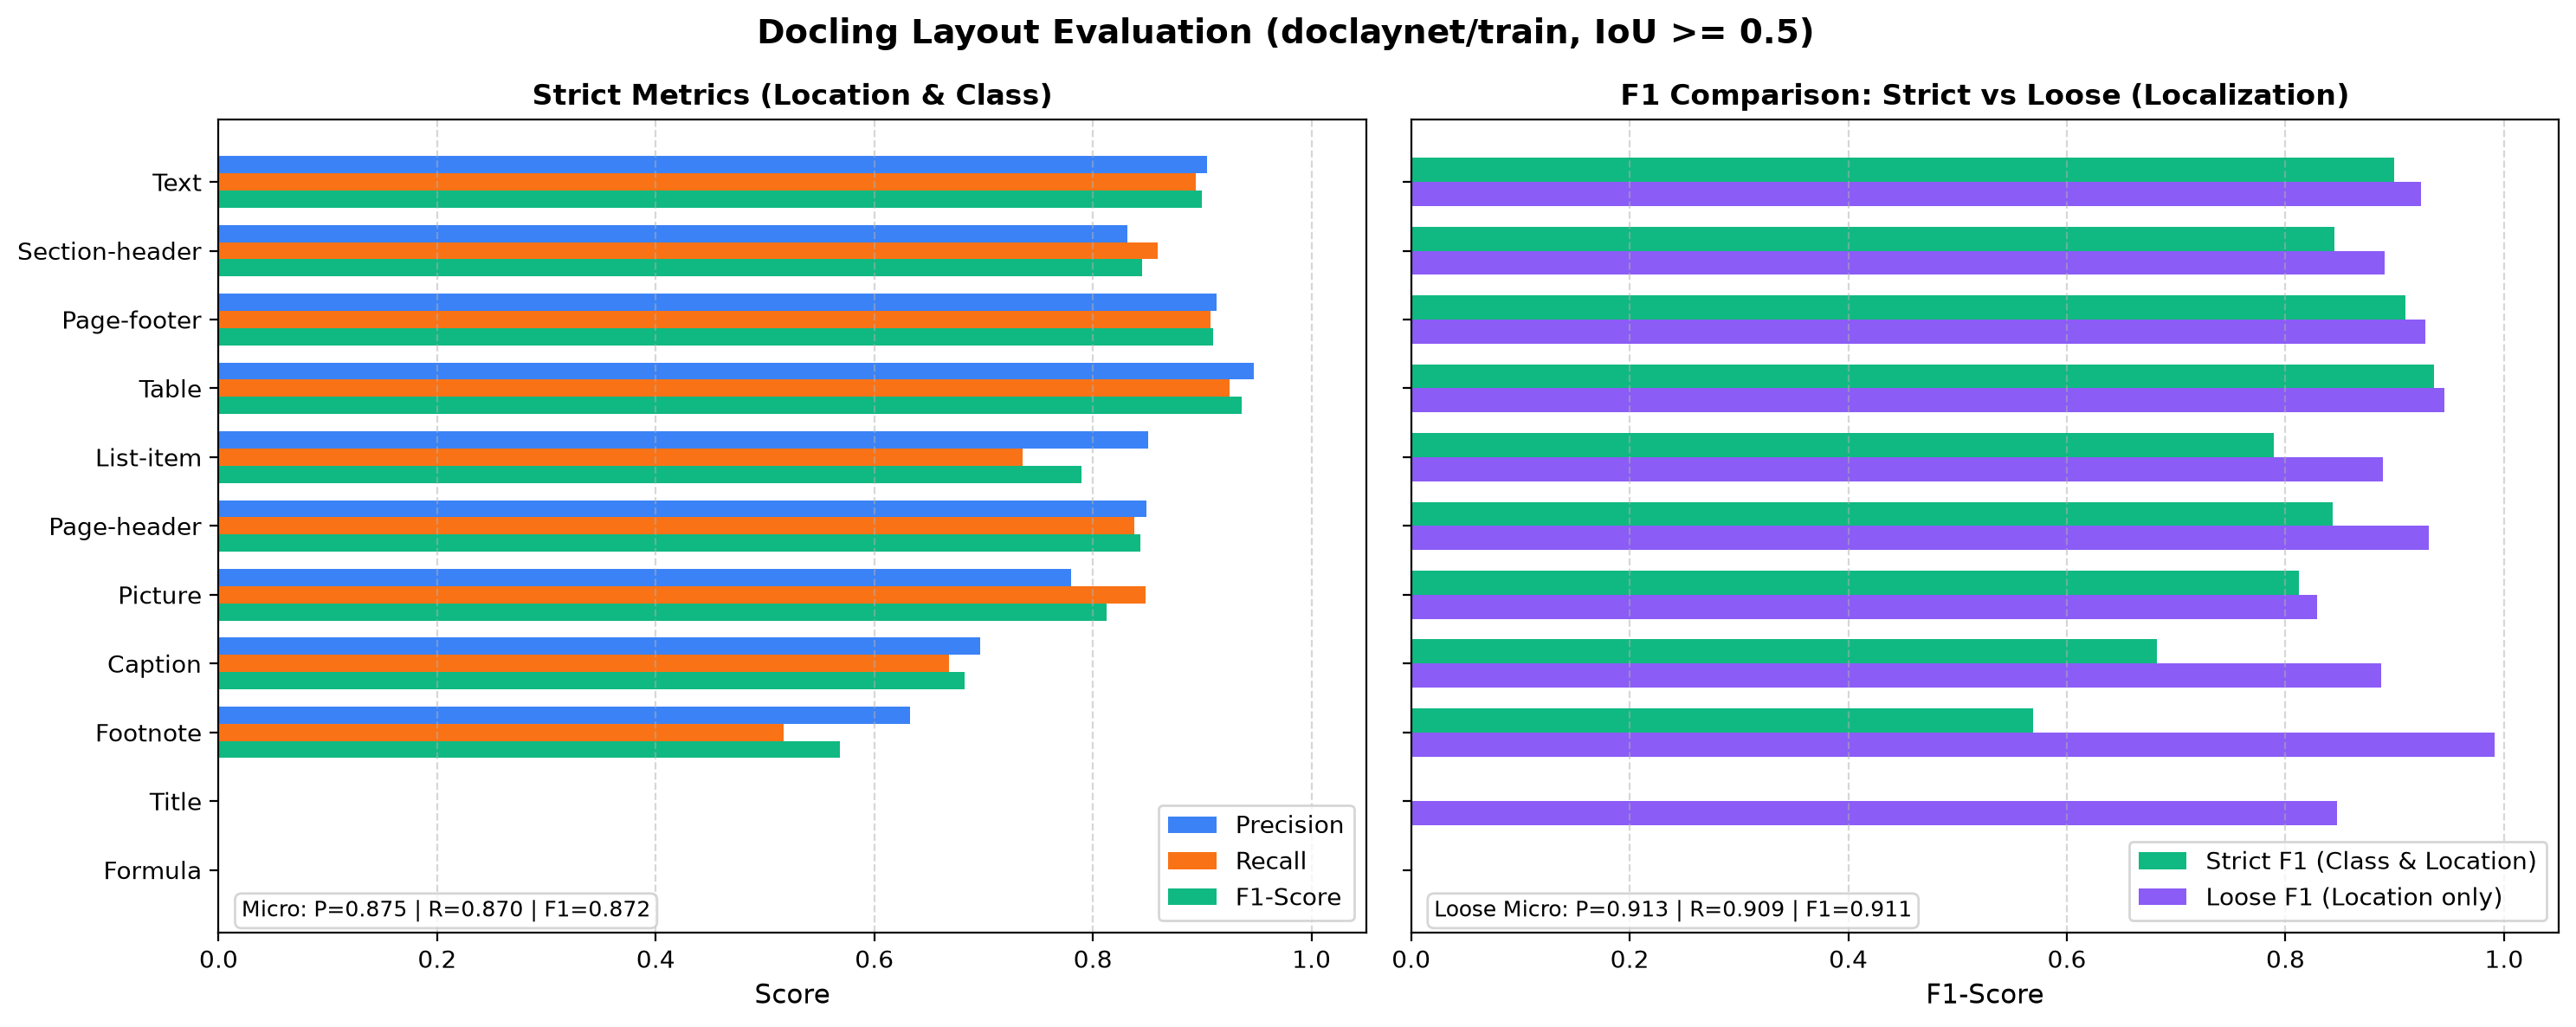

In [9]:
evaluation_script = ROOT / "scripts" / "evaluate_predictions.py"
command = [
    sys.executable,
    str(evaluation_script),
    "--method", METHOD,
    "--dataset", DATASET,
    "--split", SPLIT,
    "--iou-threshold", str(IOU_THRESHOLD),
    "--loose",
    "--plot", str(FIGURES_DIR / "metrics_chart.png"),
]
if LIMIT > 0:
    command.append("--allow-incomplete")  # chỉ đánh giá trên các ảnh đã có prediction
run_script(command)

# Hiển thị biểu đồ đánh giá
chart_file = FIGURES_DIR / "metrics_chart.png"
if chart_file.is_file():
    from IPython.display import Image as DisplayImage, display
    print(f"Evaluation Chart ({chart_file}):")
    display(DisplayImage(filename=str(chart_file)))

## 3. Ground Truth vs. Prediction Examples

Trực quan hóa đối chiếu ảnh Ground Truth và kết quả dự đoán của Docling. Ảnh kết quả được lưu tại `outputs/reports/docling_doclaynet/`.

Running: c:\Users\Admin\AppData\Local\Programs\Python\Python312\python.exe D:\DLA\DO-AN-261\visualization\scripts\visualize_predictions.py --method docling --dataset doclaynet --split train --limit 20 --output-dir D:\DLA\DO-AN-261\outputs\reports\docling_doclaynet
[viz] Ve 20 anh (docling vs ground truth) tu D:\DLA\DO-AN-261\visualization\scripts\..\..\outputs\predictions\docling\doclaynet
  [ok] 0.png
  [ok] 1.png
  [ok] 2.png
  [ok] 3.png
  [ok] 4.png
  [ok] 5.png
  [ok] 6.png
  [ok] 7.png
  [ok] 8.png
  [ok] 9.png
  [ok] 10.png
  [ok] 12.png
  [ok] 13.png
  [ok] 14.png
  [ok] 15.png
  [ok] 16.png
  [ok] 17.png
  [ok] 18.png
  [ok] 19.png
  [ok] 20.png
[viz] Xong. Anh luu tai D:\DLA\DO-AN-261\outputs\reports\docling_doclaynet
Ví dụ ảnh đối chiếu: D:\DLA\DO-AN-261\outputs\reports\docling_doclaynet\0.png


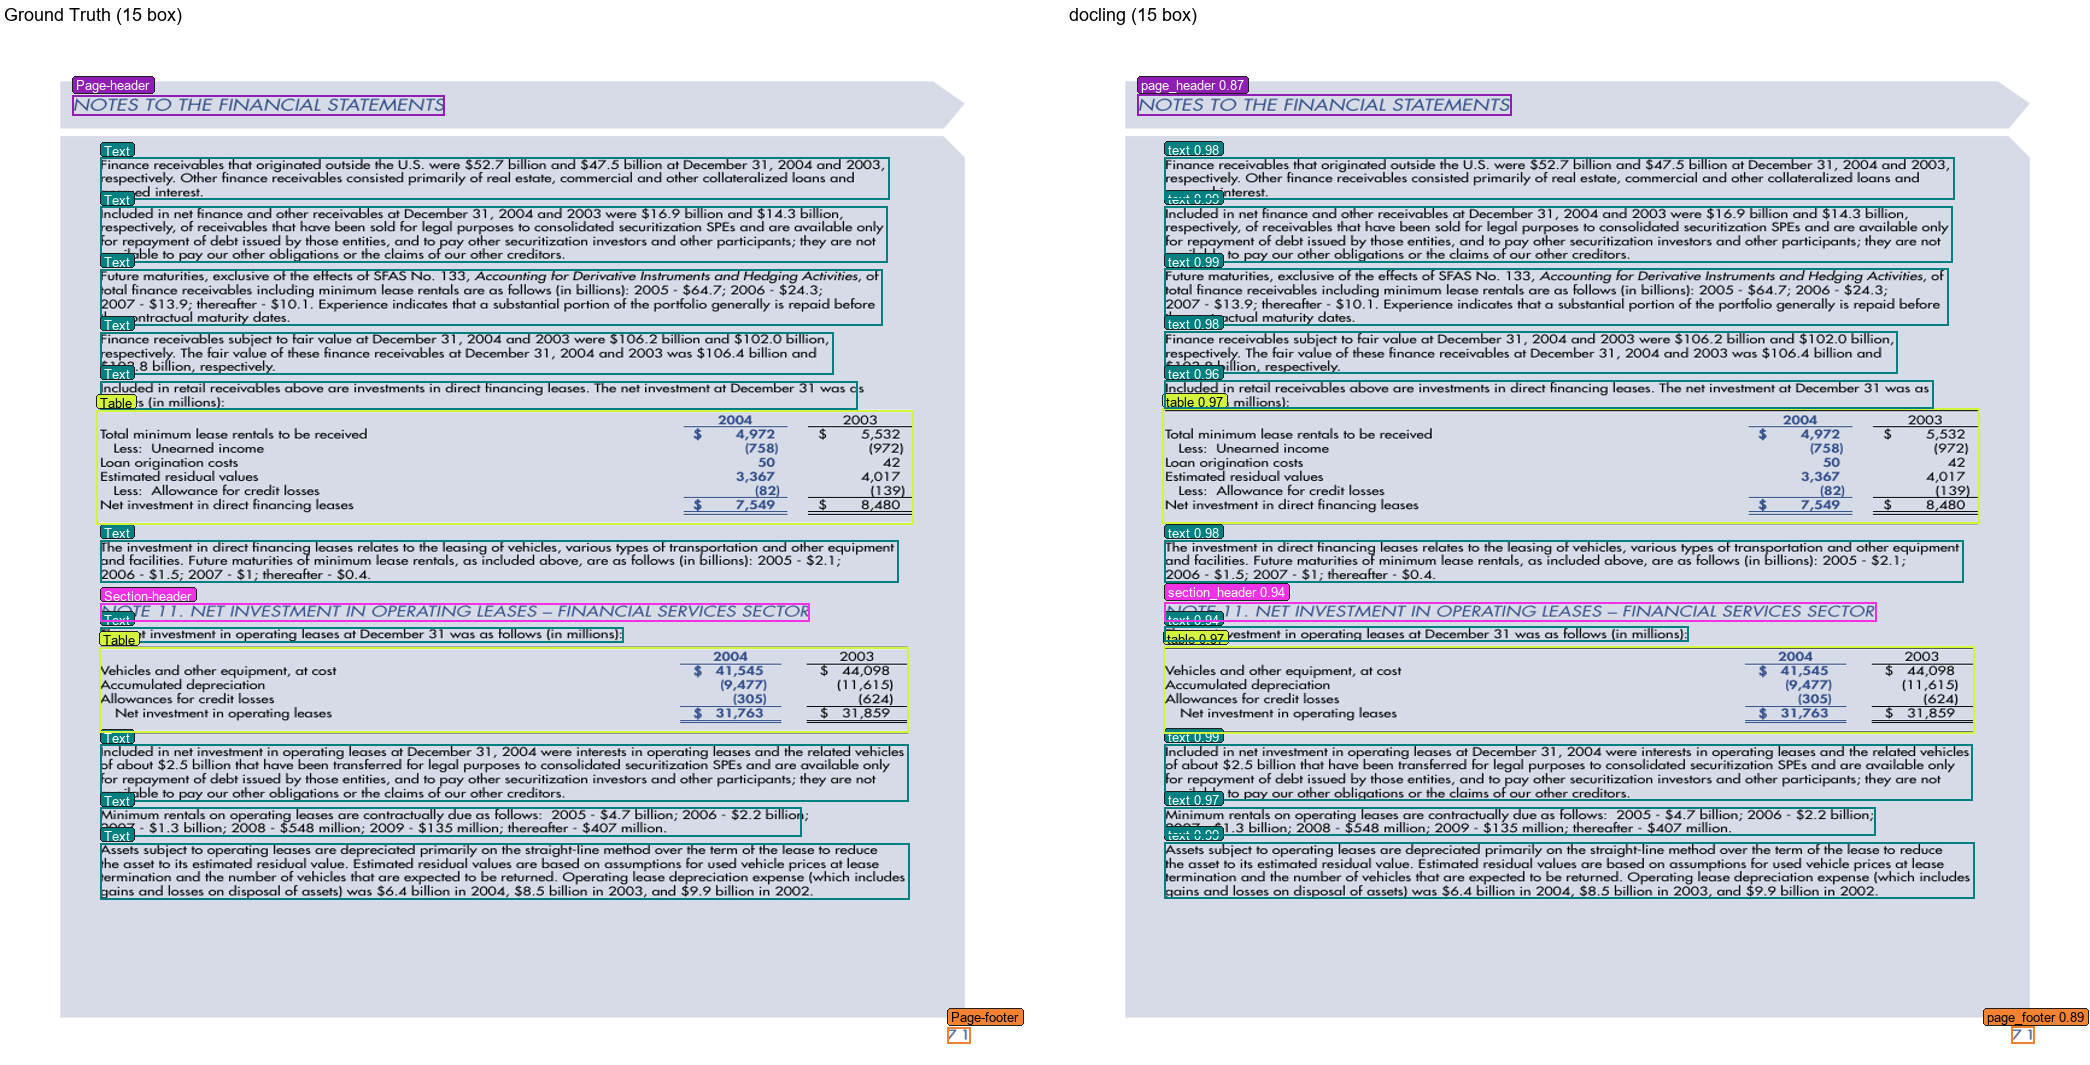

In [10]:
visualizer = ROOT / "visualization" / "scripts" / "visualize_predictions.py"
command = [
    sys.executable,
    str(visualizer),
    "--method", METHOD,
    "--dataset", DATASET,
    "--split", SPLIT,
    "--limit", str(FIGURE_LIMIT),
    "--output-dir", str(FIGURES_DIR),
]
run_script(command)

figure_files = sorted(
    FIGURES_DIR.glob("*.png"),
    key=lambda path: (0, int(path.stem)) if path.stem.isdigit() else (1, path.stem),
)
if figure_files:
    from IPython.display import Image as DisplayImage, display
    print(f"Ví dụ ảnh đối chiếu: {figure_files[0]}")
    display(DisplayImage(filename=str(figure_files[0])))
else:
    print(f"Không có hình ảnh nào trong {FIGURES_DIR}")

## Files đầu ra và báo cáo

- Predictions JSON: `outputs/predictions/docling/doclaynet/<image_id>.json`
- Ảnh đối chiếu trực quan: `outputs/reports/docling_doclaynet/<image_id>.png`
- Ground Truth COCO: `datasets/doclaynet/processed/annotations/train.json`